# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
in_ = '/hpc/group/hickeylab/fl135/pkl_data/'

i = 30
file_path = in_ + 'merfish_mouse_brain_slice' + str(i) + '.h5ad'
ad = sc.read(file_path)
ad.obs['original_clusters']=ad.obs['spa_cluster'].astype('category')
ad.obsm['spatial'] = ad.obsm['spatial'].to_numpy()[:, :2]
ad

AnnData object with n_obs × n_vars = 4408 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

In [3]:
file_path = in_ + 'merfish_mouse_brain_slice' + str(i-1) + '.h5ad'
ad_target = sc.read(file_path)
ad_target.obs['original_clusters']=ad_target.obs['spa_cluster'].astype('category')
ad_target.obsm['spatial'] = ad_target.obsm['spatial'].to_numpy()[:, :2]
ad_target

AnnData object with n_obs × n_vars = 4453 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

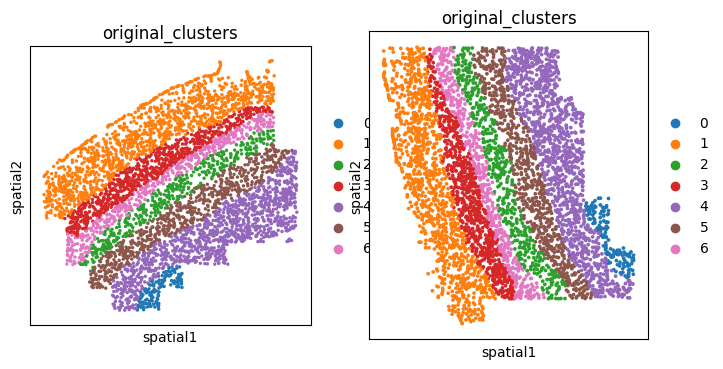

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = -spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5, draw=False)

In [6]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 1]
y = spatial_coords[:, 0]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)

In [7]:
x_target = x_target -4200
y_target = y_target -2600

x = x +2500
y = y -4100

In [8]:
# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5,draw=False)

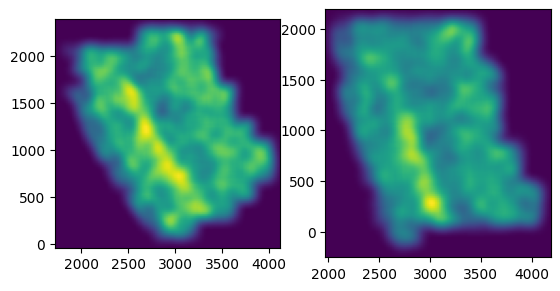

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 8min 2s, sys: 17.3 s, total: 8min 19s
Wall time: 8min 25s


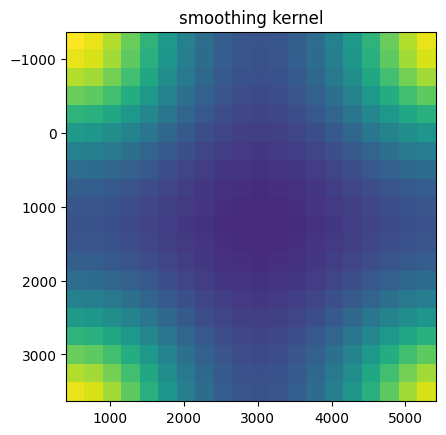

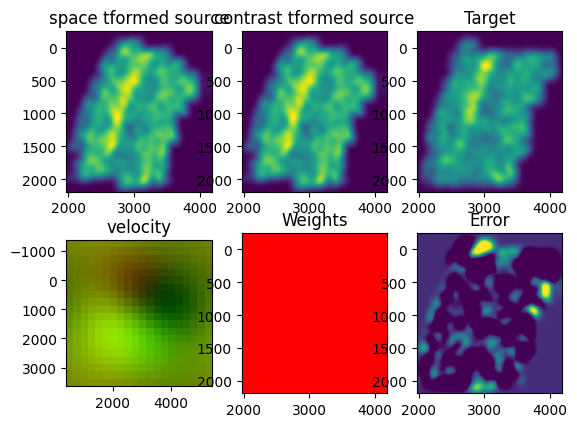

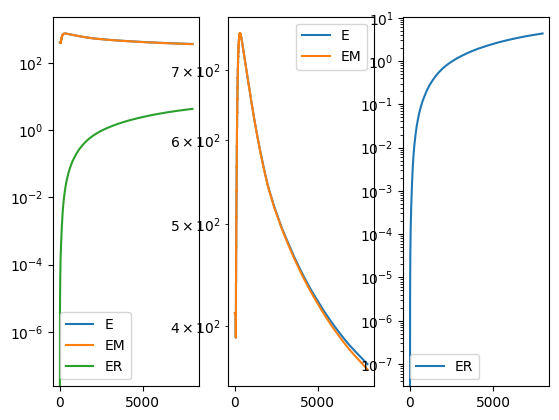

In [10]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':8000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.5, #standard deviation of artifact intensities
            'sigmaB': 0.5, #standard deviation of background intensities
            'sigmaM': 0.5, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [11]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [29]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1).astype(np.float64))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

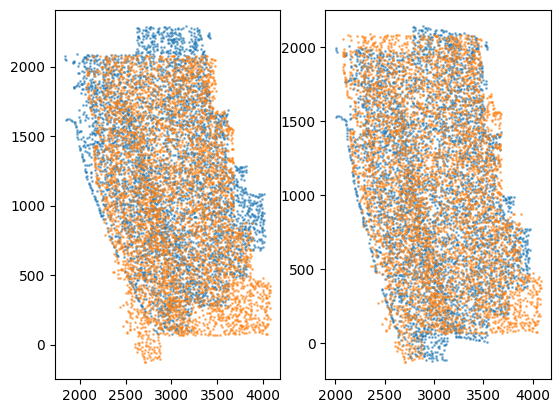

In [30]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [31]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [32]:
# Save as .pkl
alignment_df.to_pickle("29_30_AlignmentPi.pkl")

## LAA

In [33]:
def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []

    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
    print("the number of sum alignment equals 0:", str(cnt0))
    if len(sum_smallerThan0)>0:
        print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
        print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
        print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))
    res.extend([cnt0])
    return res

In [34]:
res = cal_layer_based_alignment_result_mHypothalamus(alignment, ad, ad_target)
res[0]/len(ad.obs['original_clusters'])

the number of sum alignment equals 0: 789


0.17899274047186933

In [83]:
alignment.shape

(3611, 3596)

## ARI

In [35]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [36]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.6916353564237081

## 3D

In [37]:
unique_clusters = ad.obs['original_clusters']
for jjj in range(1, 2):
    unique_clusters = sorted(np.unique(
        np.concatenate([
            unique_clusters,
            ad.obs['original_clusters']
        ])
    ))

cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))
c_dict

In [38]:
c_dict = {
    1: '#1f77b4',
    2: '#ff7f0e',
    3: '#2ca02c',
    4: '#d62728',
    5: '#9467bd',
    6: '#8c564b',
    0: '#e377c2'
    }

In [98]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

In [39]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,10013848917901580372984707123288841246,3
1,100203393073383662058607743517170536086,3
2,10021303523257862278464342827804406136,1
3,100311578293803360568962563823049856715,4
4,100390352629202609125431046988027811414,5


In [41]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 30
results1['slice'] = 'slice30'
results1

,index,original_clusters,X,Y,Z,slice
0,10013848917901580372984707123288841246,3,2747.062421,713.605867,30,slice30
1,100203393073383662058607743517170536086,3,2842.816275,593.492294,30,slice30
2,10021303523257862278464342827804406136,1,2830.647938,360.124673,30,slice30
3,100311578293803360568962563823049856715,4,3141.564985,2070.000026,30,slice30
4,100390352629202609125431046988027811414,5,3483.605406,353.676567,30,slice30
...,...,...,...,...,...,...
4403,99692850085335843874515228207629893085,4,3294.577552,1257.309972,30,slice30
4404,99790281797421425057431892704770640558,6,3475.095160,79.933668,30,slice30
4405,99822782213450297785946183410110297362,1,2527.853036,457.456515,30,slice30
4406,9982378635862811018916060302402286542,1,2515.326680,1108.836342,30,slice30


In [42]:
results1['celltype_colors'] = results1['original_clusters'].replace(c_dict)
results1

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,10013848917901580372984707123288841246,3,2747.062421,713.605867,30,slice30,#2ca02c
1,100203393073383662058607743517170536086,3,2842.816275,593.492294,30,slice30,#2ca02c
2,10021303523257862278464342827804406136,1,2830.647938,360.124673,30,slice30,#1f77b4
3,100311578293803360568962563823049856715,4,3141.564985,2070.000026,30,slice30,#d62728
4,100390352629202609125431046988027811414,5,3483.605406,353.676567,30,slice30,#9467bd
...,...,...,...,...,...,...,...
4403,99692850085335843874515228207629893085,4,3294.577552,1257.309972,30,slice30,#d62728
4404,99790281797421425057431892704770640558,6,3475.095160,79.933668,30,slice30,#8c564b
4405,99822782213450297785946183410110297362,1,2527.853036,457.456515,30,slice30,#1f77b4
4406,9982378635862811018916060302402286542,1,2515.326680,1108.836342,30,slice30,#1f77b4


In [43]:
results1.to_csv("30.csv", index=False)